# Customer Churn Feature Engineering
**Atharva Sandeep Raut | 2026EM1100070**  
MSc — BITS Pilani Digital | Graded Assignment 1 | 20 marks  
Finalized: 17 November 2026

I prepare customer account data for future churn modelling in a subscription cloud communications and digital services organization. My aim is a compact, interpretable and reusable feature engineering process; I do not train a churn classifier.

I use the confirmed **`Data/Graded_Assignment_2_Dataset.csv`**. The LMS calls the file “Graded_Assignment_1_Dataset.csv”, but the supplied file has been confirmed as correct. I leave it unchanged. Parts A–E follow the task structure (4+6+4+4+2); I also check coverage against the final LMS rubric (4+6+5+5).

**Reading guide.** Part A establishes the evidence; Part B explains preprocessing; Part C constructs and selects features; Part D integrates and validates the pipeline and evaluates PCA; Part E reflects on the choices. Code outputs have labels so their purpose remains clear when read independently.

**Reproducibility.** Run all cells with Python 3 and pandas, NumPy, Matplotlib, seaborn and scikit-learn installed. The notebook needs only the supplied CSV, with no network downloads or custom modules. It runs from this project folder or its parent. All measurements are assumed to be available before a future churn outcome; the file has no timestamps with which to verify that assumption.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
from IPython.display import display
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import (
    FunctionTransformer,
    OneHotEncoder,
    RobustScaler,
    StandardScaler,
)
from sklearn.impute import SimpleImputer
from sklearn.decomposition import PCA
from sklearn.base import clone

sns.set_theme(style="whitegrid", context="notebook", palette="colorblind")
plt.rcParams.update(
    {"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False}
)
pd.set_option("display.max_columns", 12)
pd.set_option("display.max_rows", 80)
pd.set_option("display.max_colwidth", None)
pd.set_option("display.precision", 3)
data_path = Path("Data/Graded_Assignment_2_Dataset.csv")
if not data_path.exists():
    data_path = Path("Feature_Engineering") / data_path
if not data_path.exists():
    raise FileNotFoundError("Keep the supplied CSV under Feature_Engineering/Data/.")

# 'None' denotes no internet / no support package, rather than missing data.
raw = pd.read_csv(data_path, keep_default_na=False, na_values=[""])
print("Environment: pandas", pd.__version__, "| scikit-learn", sklearn.__version__)
print("Input file:", data_path)
print("Raw customer records and variables:", raw.shape)
print("Table A1 — first five customer records (selected fields)")
display(
    raw[
        [
            "Customer_ID",
            "Age",
            "Tenure_Months",
            "Internet_Service_Type",
            "Monthly_Charges",
            "Churn",
        ]
    ].head()
)


Environment: pandas 3.1.1 | scikit-learn 1.9.1
Input file: Data\Graded_Assignment_2_Dataset.csv
Raw customer records and variables: (5000, 32)
Table A1 — first five customer records (selected fields)


,Customer_ID,Age,Tenure_Months,Internet_Service_Type,Monthly_Charges,Churn
0,CUST100001,46,45,None,86.48,0
1,CUST100002,39,6,Fiber Optic,95.11,1
2,CUST100003,48,21,DSL,80.83,0
3,CUST100004,59,46,Fiber Optic,80.33,0
4,CUST100005,38,12,None,81.60,0


## Part A — Understanding the dataset
I first check the entire file's inventory and then reserve 20% of customers for transformation checks. The full-file counts describe the supplied data; distributions, redundancy decisions and preprocessing design below use the 4,000 training rows. No holdout labels are used to select features. This split demonstrates correct preprocessing, rather than estimating model performance.

In [2]:
assert raw.shape == (5000, 32)
assert raw.Customer_ID.notna().all() and raw.Customer_ID.is_unique
assert set(raw.Churn.unique()) == {0, 1}
print(
    "Full-file inventory — duplicate records:",
    raw.duplicated().sum(),
    "| duplicate customer identifiers:",
    raw.Customer_ID.duplicated().sum(),
)
print("Table A2 — raw missing values; literal 'None' categories are preserved")
missing = raw.isna().sum().loc[lambda s: s.gt(0)]
missing_table = pd.DataFrame(
    {"Missing rows": missing, "Percent": missing / len(raw) * 100}
)
display(missing_table)
X = raw.drop(columns="Churn")
y = raw.Churn.copy()
X_train, X_holdout, y_train, y_holdout = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)
print("Table A3 — stratified partition sizes and target balance")
display(
    pd.DataFrame(
        {
            "Rows": [len(raw), len(X_train), len(X_holdout)],
            "Churned": [y.sum(), y_train.sum(), y_holdout.sum()],
            "Churn percent": [
                100 * y.mean(),
                100 * y_train.mean(),
                100 * y_holdout.mean(),
            ],
        },
        index=["Full file", "Training", "Holdout"],
    )
)


Full-file inventory — duplicate records: 0 | duplicate customer identifiers: 0
Table A2 — raw missing values; literal 'None' categories are preserved


,Missing rows,Percent
Marital_Status,97,1.94
Total_Charges,164,3.28
Avg_Resolution_Time_Hours,325,6.50
Customer_Satisfaction_Score,230,4.60
Engagement_Index,221,4.42


Table A3 — stratified partition sizes and target balance


,Rows,Churned,Churn percent
Full file,5000,2349,46.980
Training,4000,1879,46.975
Holdout,1000,470,47.000


In [3]:
# Semantic types are separate from pandas storage types.
ordinal = ["Customer_Satisfaction_Score", "NPS_Score", "System_Stability_Score"]
nominal = [
    "Gender",
    "Region",
    "Marital_Status",
    "Contract_Type",
    "Payment_Method",
    "Internet_Service_Type",
    "Device_Protection",
    "Tech_Support_Tier",
]
counts = [
    "Tenure_Months",
    "Num_Streaming_Services",
    "Monthly_Logins",
    "Inactivity_Days",
    "Late_Payments_Count",
    "Support_Tickets_Count",
    "Unresolved_Tickets_Count",
    "Service_Disruption_Events",
]
types = []
for col in raw.columns:
    kind = (
        "Identifier"
        if col == "Customer_ID"
        else (
            "Target: binary"
            if col == "Churn"
            else (
                "Binary: Yes/No"
                if col == "Paperless_Billing"
                else (
                    "Ordered category"
                    if col in ["Charge_Band", "Tenure_Segment"]
                    else (
                        "Ordinal rating"
                        if col in ordinal
                        else (
                            "Nominal category"
                            if col in nominal
                            else (
                                "Discrete numeric / count"
                                if col in counts
                                else "Continuous numeric"
                            )
                        )
                    )
                )
            )
        )
    )
    types.append(
        [
            col,
            kind,
            str(raw[col].dtype),
            X_train[col].nunique() if col != "Churn" else 2,
        ]
    )
print("Table A4 — all 32 variables: meaning, storage and training cardinality")
display(
    pd.DataFrame(
        types,
        columns=["Variable", "Semantic type", "Stored dtype", "Distinct nonmissing"],
    )
)
print("Table A5 — training numerical descriptive statistics")
display(X_train.select_dtypes(include="number").describe().T)
print("Table A6 — training category frequencies, including missing labels")
category_rows = []
for col in X_train.select_dtypes(exclude="number").columns.drop("Customer_ID"):
    for label, n in X_train[col].value_counts(dropna=False).items():
        category_rows.append([col, str(label), n, round(100 * n / len(X_train), 2)])
display(pd.DataFrame(category_rows, columns=["Feature", "Category", "Rows", "Percent"]))
print("Ordinal rating levels observed in training:")
for col in ordinal:
    print(col, sorted(X_train[col].dropna().unique()))


Table A4 — all 32 variables: meaning, storage and training cardinality


,Variable,Semantic type,Stored dtype,Distinct nonmissing
0,Customer_ID,Identifier,str,4000
1,Age,Continuous numeric,int64,58
2,Gender,Nominal category,str,3
3,Region,Nominal category,str,5
4,Marital_Status,Nominal category,str,3
5,Tenure_Months,Discrete numeric / count,int64,72
6,Tenure_Years,Continuous numeric,float64,60
7,Contract_Type,Nominal category,str,3
8,Payment_Method,Nominal category,str,4
9,Paperless_Billing,Binary: Yes/No,str,2


Table A5 — training numerical descriptive statistics


,count,mean,std,min,25%,50%,75%,max
Age,4000.0,40.697,11.616,18.00,33.000,41.000,48.000,75.00
Tenure_Months,4000.0,21.983,19.870,1.00,6.000,16.000,32.250,72.00
Tenure_Years,4000.0,1.833,1.656,0.10,0.500,1.300,2.725,6.00
Num_Streaming_Services,4000.0,1.653,1.232,0.00,1.000,1.000,3.000,4.00
Avg_Daily_Usage_Minutes,4000.0,127.345,89.243,4.00,71.375,110.600,162.725,969.70
Monthly_Logins,4000.0,18.059,4.231,5.00,15.000,18.000,21.000,35.00
Inactivity_Days,4000.0,12.341,11.482,1.00,4.000,9.000,17.000,60.00
Monthly_Charges,4000.0,84.921,25.307,20.00,66.668,84.025,102.577,165.86
Estimated_Annual_Charges,4000.0,1019.146,303.905,231.30,800.860,1010.980,1231.342,1992.80
Total_Charges,3874.0,1837.121,1834.534,18.96,464.440,1246.285,2596.548,10809.01


Table A6 — training category frequencies, including missing labels


,Feature,Category,Rows,Percent
0,Gender,Female,1949,48.73
1,Gender,Male,1930,48.25
2,Gender,Non-Binary,121,3.02
3,Region,North,1026,25.65
4,Region,West,1015,25.38
5,Region,South,781,19.52
6,Region,East,777,19.43
7,Region,Central,401,10.03
8,Marital_Status,Married,2018,50.45
9,Marital_Status,Single,1302,32.55


Ordinal rating levels observed in training:
Customer_Satisfaction_Score [np.float64(1.0), np.float64(2.0), np.float64(3.0), np.float64(4.0), np.float64(5.0)]
NPS_Score [np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(9), np.int64(10)]
System_Stability_Score [np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5)]


The file has one unique customer per row, with no duplicate records. There are 2,349 churned customers (46.98%). True blanks occur in five fields: marital status (97), total charges (164), resolution time (325), satisfaction (230), and engagement (221). “None” is an observed service/package label, so accepting pandas' default missing-token list would incorrectly erase 748 internet and 2,464 support-package values.

The satisfaction and stability scores have ordered levels 1–5, while `NPS_Score` contains individual responses 0–10. It is not an aggregate net promoter percentage. I retain their ordering, without applying logarithms or claiming equal psychological distances. Support tiers describe packages; I use nominal encoding because their service differences are not quantified. The charge and tenure bands have a genuine order but may add little beyond their continuous sources.

Figure A1 — training numerical distributions across business domains


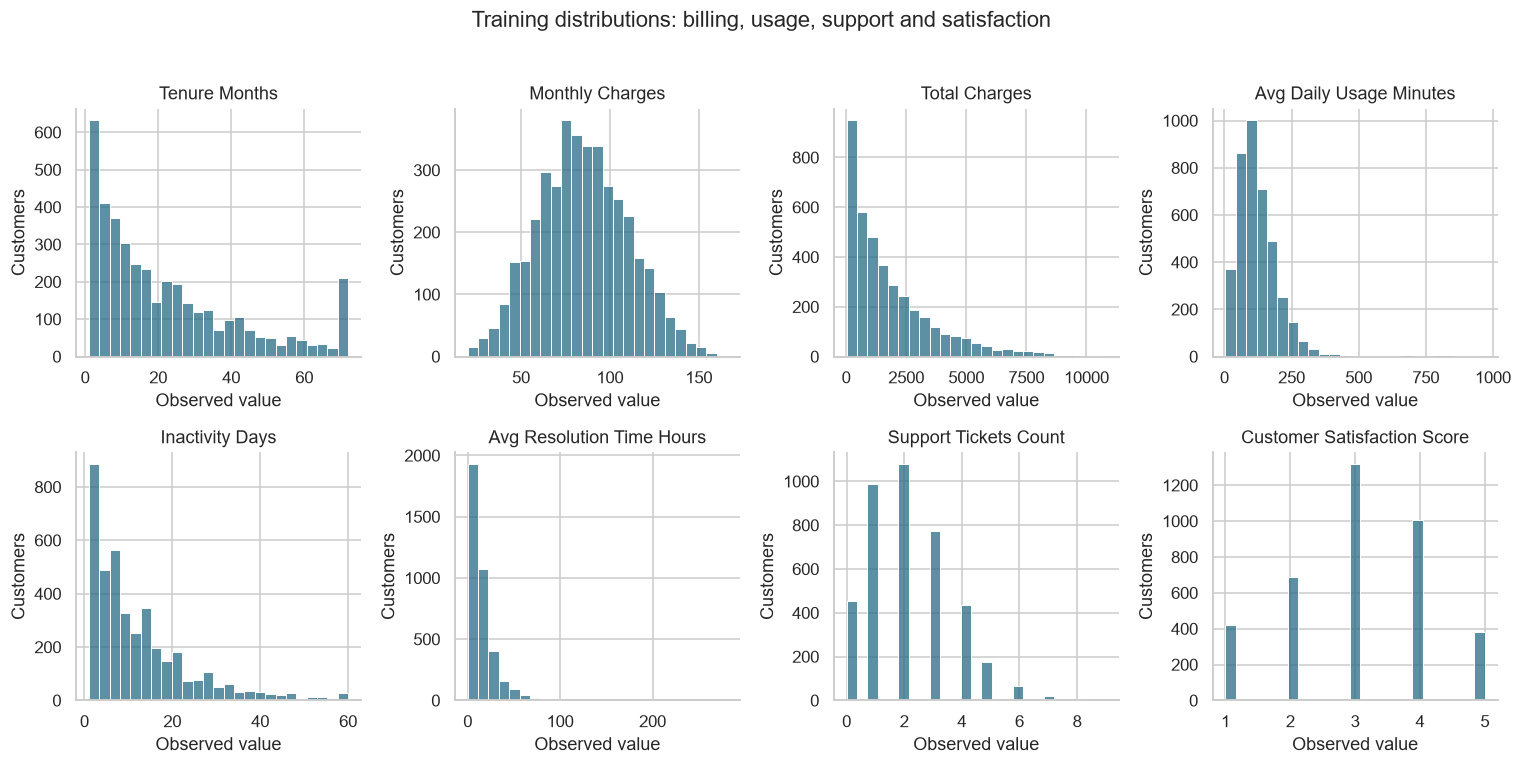

Table A7 — training missingness, asymmetry and statistical outlier flags


,Missing,Skewness,IQR flagged,Minimum,Maximum
Age,0,0.131,27,18.00,75.00
Tenure_Months,0,1.086,191,1.00,72.00
Tenure_Years,0,1.086,0,0.10,6.00
Num_Streaming_Services,0,0.372,0,0.00,4.00
Avg_Daily_Usage_Minutes,0,3.282,114,4.00,969.70
Monthly_Logins,0,0.258,12,5.00,35.00
Inactivity_Days,0,1.655,206,1.00,60.00
Monthly_Charges,0,0.130,6,20.00,165.86
Estimated_Annual_Charges,0,0.131,6,231.30,1992.80
Total_Charges,126,1.576,185,18.96,10809.01


In [4]:
print("Figure A1 — training numerical distributions across business domains")
plot_columns = [
    "Tenure_Months",
    "Monthly_Charges",
    "Total_Charges",
    "Avg_Daily_Usage_Minutes",
    "Inactivity_Days",
    "Avg_Resolution_Time_Hours",
    "Support_Tickets_Count",
    "Customer_Satisfaction_Score",
]
fig, axes = plt.subplots(2, 4, figsize=(14, 6.8))
for ax, col in zip(axes.flat, plot_columns):
    sns.histplot(X_train[col], bins=25, ax=ax, color="#286B86")
    ax.set(title=col.replace("_", " "), xlabel="Observed value", ylabel="Customers")
fig.suptitle("Training distributions: billing, usage, support and satisfaction", y=1.02)
fig.tight_layout()
plt.show()

numeric_train = X_train.select_dtypes(include="number")
q1, q3 = numeric_train.quantile(0.25), numeric_train.quantile(0.75)
iqr = q3 - q1
outliers = (
    (numeric_train.lt(q1 - 1.5 * iqr)) | (numeric_train.gt(q3 + 1.5 * iqr))
).sum()
quality_stats = pd.DataFrame(
    {
        "Missing": numeric_train.isna().sum(),
        "Skewness": numeric_train.skew(),
        "IQR flagged": outliers,
        "Minimum": numeric_train.min(),
        "Maximum": numeric_train.max(),
    }
)
print("Table A7 — training missingness, asymmetry and statistical outlier flags")
display(quality_stats.round(3))


Table A8 — training domain checks and structural missingness


,Rows / cells
Training inactivity outside 0–31 days,299
Training contradictory device/internet status,1016
Training unresolved count above total tickets,0
Training customers without support tickets,456
Observed positive resolution time without tickets,0
Missing resolution time without tickets,28
Blank/whitespace string cells,0
Negative numerical cells,0


Table A9 — training resolution-time missingness by support history


,size,count,min,max
No support tickets,,,,
False,3544,3316,0.9,280.6
True,456,428,0.0,0.0


Table A10 — training cross-system device-protection inconsistencies


Device_Protection,No,No Internet,Yes
Internet_Service_Type,,,
DSL,738,243,581
Fiber Optic,940,268,640
None,293,85,212


Figure A2 — missing values in the supplied file; blanks only


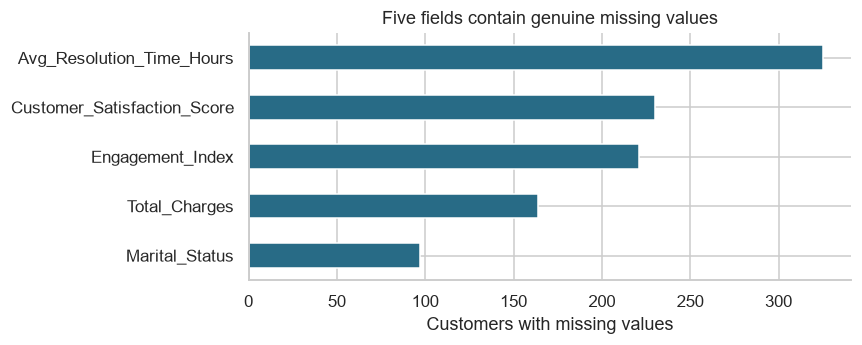

In [5]:
# Separate logical inconsistencies from merely unusual values.
invalid_inactivity = ~X_train.Inactivity_Days.between(0, 31)
device_conflict = X_train.Device_Protection.eq(
    "No Internet"
) != X_train.Internet_Service_Type.eq("None")
zero_support = X_train.Support_Tickets_Count.eq(0)
quality_checks = pd.Series(
    {
        "Training inactivity outside 0–31 days": int(invalid_inactivity.sum()),
        "Training contradictory device/internet status": int(device_conflict.sum()),
        "Training unresolved count above total tickets": int(
            (X_train.Unresolved_Tickets_Count > X_train.Support_Tickets_Count).sum()
        ),
        "Training customers without support tickets": int(zero_support.sum()),
        "Observed positive resolution time without tickets": int(
            (zero_support & X_train.Avg_Resolution_Time_Hours.gt(0)).sum()
        ),
        "Missing resolution time without tickets": int(
            (zero_support & X_train.Avg_Resolution_Time_Hours.isna()).sum()
        ),
        "Blank/whitespace string cells": int(
            sum(
                X_train[c].dropna().str.strip().eq("").sum()
                for c in X_train.select_dtypes(exclude="number")
            )
        ),
        "Negative numerical cells": int((numeric_train < 0).sum().sum()),
    }
)
print("Table A8 — training domain checks and structural missingness")
display(quality_checks.to_frame("Rows / cells"))
print("Table A9 — training resolution-time missingness by support history")
display(
    X_train.groupby(
        zero_support.rename("No support tickets")
    ).Avg_Resolution_Time_Hours.agg(["size", "count", "min", "max"])
)
print("Table A10 — training cross-system device-protection inconsistencies")
display(pd.crosstab(X_train.Internet_Service_Type, X_train.Device_Protection))

print("Figure A2 — missing values in the supplied file; blanks only")
fig, ax = plt.subplots(figsize=(8, 3.3))
missing.sort_values().plot.barh(ax=ax, color="#286B86")
ax.set(
    xlabel="Customers with missing values",
    ylabel="",
    title="Five fields contain genuine missing values",
)
fig.tight_layout()
plt.show()


The training data contain 299 inactivity values above 31 days. Because the description places this measure within the previous month, I treat them as invalid under a stated 31-day maximum. A cross-month interpretation would require a different rule and source confirmation. I replace invalid values with missing, retain a missingness indicator and impute later; I do not silently cap them to 31.

Device protection conflicts with internet status in 1,016 training rows. For example, “No Internet” appears for DSL/fiber customers, and some “None” internet customers have Yes/No protection labels. I cannot establish which source is correct. I exclude `Device_Protection` from model inputs rather than invent corrections, accepting the loss of otherwise valid protection information. The whole-file audit later reports the extent of these issues without changing the training decisions.

Zero-ticket customers have observed resolution times of zero, not positive durations; 28 such training rows have missing time. I interpret these as “not applicable” and fill only these missing times with zero. Missing resolution times for customers with tickets remain unknown and need imputation. This is a business convention supported by the observed pattern, not proof about upstream systems. IQR flags alone do not justify deleting customers: high usage, charges and resolution times can be plausible. I retain valid extremes and reduce their influence with selective logarithms and robust scaling.

Figure A3 — Pearson relationships among training numerical predictors


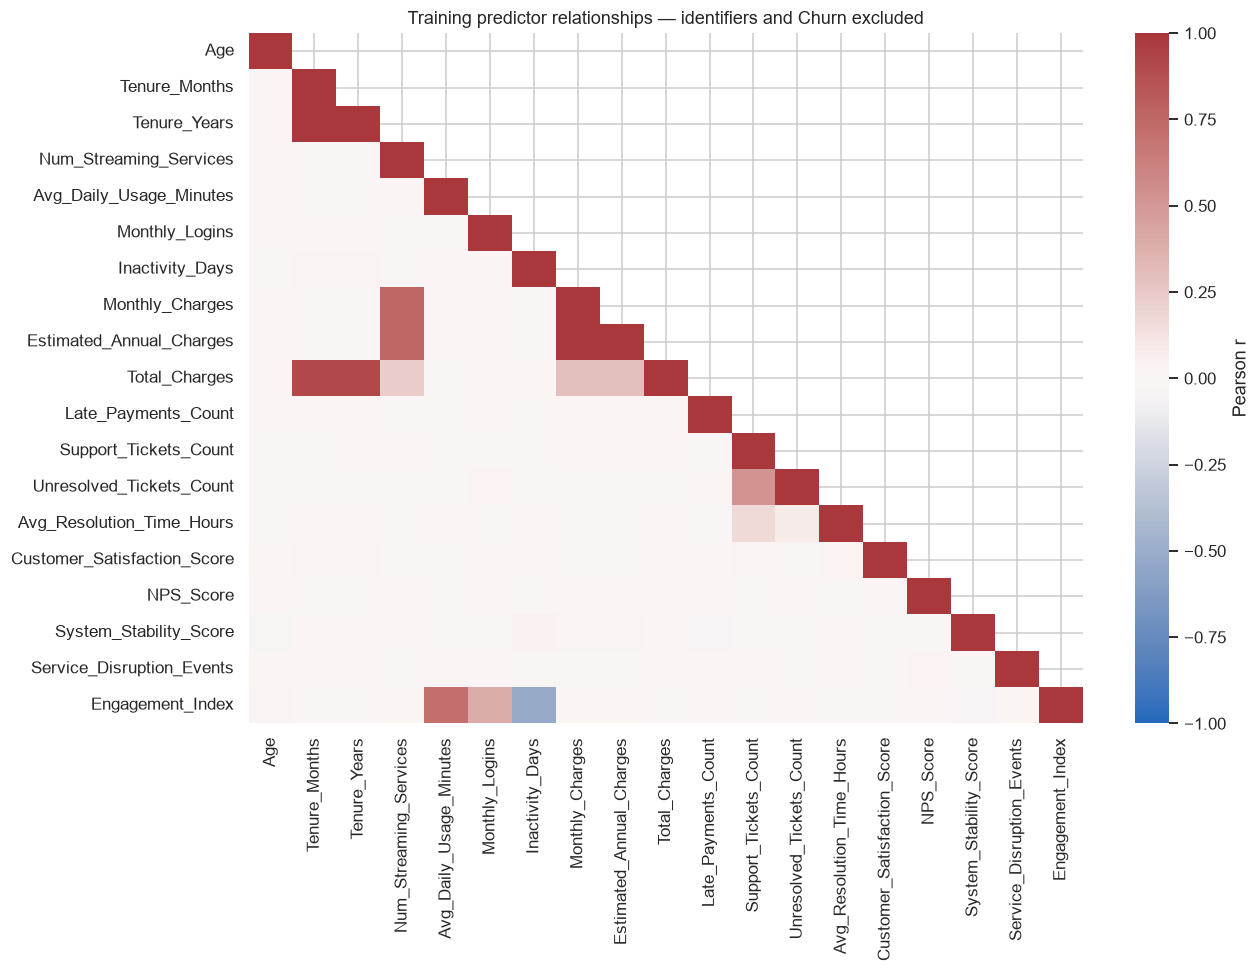

Table A11 — pairs with |r| ≥ 0.75 (screening evidence, not an automatic deletion rule)


Pearson r
Tenure_Months          Tenure_Years                  1.000
Monthly_Charges        Estimated_Annual_Charges      0.999
Tenure_Months          Total_Charges                 0.909
Tenure_Years           Total_Charges                 0.909
Num_Streaming_Services Monthly_Charges               0.752
                       Estimated_Annual_Charges      0.751

Figure A4 — training subscription composition and descriptive churn rates


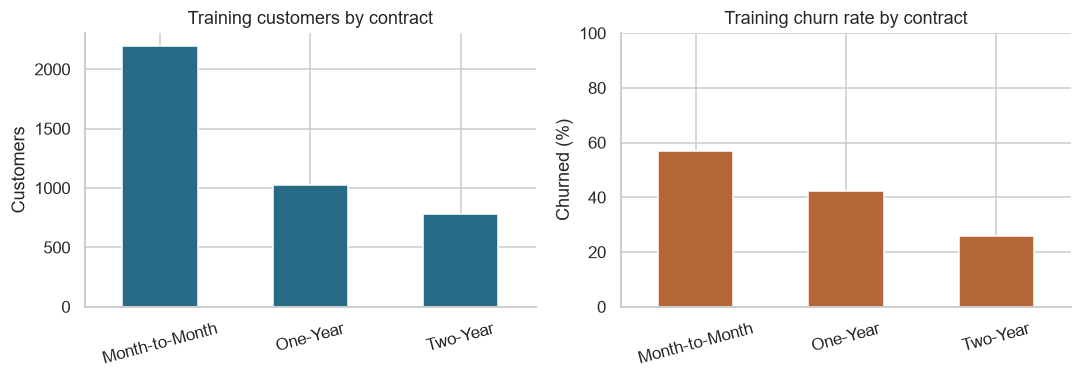

,Training customers,Churn proportion
Contract,,
Month-to-Month,2194,0.567
One-Year,1029,0.422
Two-Year,777,0.257


In [6]:
print("Figure A3 — Pearson relationships among training numerical predictors")
corr = numeric_train.corr()
fig, ax = plt.subplots(figsize=(12, 9))
sns.heatmap(
    corr,
    mask=np.triu(np.ones_like(corr, dtype=bool), k=1),
    cmap="vlag",
    center=0,
    vmin=-1,
    vmax=1,
    ax=ax,
    cbar_kws={"label": "Pearson r"},
)
ax.set_title("Training predictor relationships — identifiers and Churn excluded")
fig.tight_layout()
plt.show()
upper = corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool)).stack()
print(
    "Table A11 — pairs with |r| ≥ 0.75 (screening evidence, not an automatic deletion rule)"
)
display(
    upper[upper.abs().ge(0.75)]
    .sort_values(ascending=False)
    .rename("Pearson r")
    .to_frame()
)

print("Figure A4 — training subscription composition and descriptive churn rates")
group = (
    pd.DataFrame({"Contract": X_train.Contract_Type, "Churn": y_train})
    .groupby("Contract")
    .Churn.agg(["size", "mean"])
)
fig, axes = plt.subplots(1, 2, figsize=(10, 3.6))
group["size"].plot.bar(ax=axes[0], color="#286B86", rot=15)
(100 * group["mean"]).plot.bar(ax=axes[1], color="#B46638", rot=15)
axes[0].set(title="Training customers by contract", ylabel="Customers", xlabel="")
axes[1].set(
    title="Training churn rate by contract",
    ylabel="Churned (%)",
    xlabel="",
    ylim=(0, 100),
)
fig.tight_layout()
plt.show()
display(
    group.rename(columns={"size": "Training customers", "mean": "Churn proportion"})
)


**What I carry forward.** Tenure, total charges, usage and resolution times are right-skewed. Charges and tenure have near-duplicate representations, while lifetime charges are strongly related to tenure but describe a different commercial quantity. I investigate those relationships explicitly in Part C. Counts and bounded scores do not all need the same transformation. Missing service/package labels must be distinguished from actual missing data. The contract comparison is descriptive and does not establish causation or a basis for automatically dropping weakly associated features.

## Part B — Designing a feature engineering strategy
I choose a simple strategy driven by the training evidence. Learned medians, modes, encodings and scaling parameters will be fitted inside a `ColumnTransformer`. Deterministic cleaning and ratio construction happen before imputation, so an unavailable source produces an unavailable ratio rather than a ratio of independently imputed values.

| Feature/group | Evidence and treatment | Reason and alternative considered |
|---|---|---|
| Literal None categories | Preserve when reading CSV | They represent no service/package; default NA parsing would lose information. |
| Inactivity | Values above 31 become missing; median + indicator | Respect the stated monthly window; clipping would disguise invalid entries. |
| Missing resolution time | Zero only if ticket count is zero; otherwise median + indicator | Zero is not appropriate for customers with support history. |
| Total charges, resolution time, engagement | Training median + indicators | Missingness is modest; medians resist extremes. Row deletion would discard customers; multivariate imputation adds assumptions. |
| Satisfaction | Training most-frequent level + indicator | Keeps the imputed value on the observed ordinal scale; a continuous mean creates intermediate ratings. |
| Marital status | Explicit Missing category | Avoid guessing personal status; mode imputation would overstate the largest group. |
| Tenure, usage, lifetime charges, resolution time | `log1p`, then robust scale | All are nonnegative and training skewness falls in absolute value; do not log bounded ratings or every count. |
| Remaining numerical measures | Median if needed; robust scale | IQR scaling reduces sensitivity to extremes, with no record deletion. Standard scaling is a reasonable alternative for less extreme measures. |
| Ratings and Paperless_Billing | Keep ratings in original units; Yes=1 / No=0 | Ordering is genuine; rating distances remain a modelling assumption. No redundant binary dummies. |
| Nominal categories and support packages | One-hot; unseen levels give an all-zero block | Avoid invented ordering; low cardinality does not justify target encoding. |

I keep all one-hot levels to avoid choosing an arbitrary reference in a model-independent feature dataset. A later unregularized linear model with an intercept should drop one level per category. Missingness indicators describe data availability, not a confirmed cause of churn. New missingness in a field that was complete during fitting is still imputed, but does not create a new indicator column.

In [7]:
log_columns = [
    "Tenure_Months",
    "Avg_Daily_Usage_Minutes",
    "Total_Charges",
    "Avg_Resolution_Time_Hours",
]
print("Table B1 — training skewness before and after log1p (observed values)")
display(
    pd.DataFrame(
        {
            "Original skewness": X_train[log_columns].skew(),
            "log1p skewness": np.log1p(X_train[log_columns]).skew(),
        }
    )
)
assert (X_train[log_columns].dropna() >= 0).all().all()
print("The four selected log inputs have a valid nonnegative domain.")


Table B1 — training skewness before and after log1p (observed values)


,Original skewness,log1p skewness
Tenure_Months,1.086,-0.374
Avg_Daily_Usage_Minutes,3.282,-0.419
Total_Charges,1.576,-0.548
Avg_Resolution_Time_Hours,3.905,-0.740


The four selected log inputs have a valid nonnegative domain.


## Part C — Feature construction and feature selection
I construct two ratios rather than an arbitrary composite risk score. They add nonlinear comparisons to the retained source measures; they do not create new independent information.

| New feature | Definition and business interpretation | Missing/zero handling and limitations |
|---|---|---|
| `Unresolved_Support_Ratio` | Unresolved tickets / total support tickets: backlog relative to contact volume | Zero if both counts are zero; otherwise require a positive total and 0 ≤ unresolved ≤ total. Unknown/inconsistent inputs produce missing, then training-median imputation. Assumes current unresolved tickets belong to the same previous-year ticket cohort; this needs operational confirmation. |
| `Historical_Charge_Ratio` | Total charges / (tenure months × current monthly charge): historical average monthly billing relative to today's price | Require positive tenure and current charge; unknown input gives missing. A value near 1 means historical average billing resembles the current fee. Assumes tenure and cumulative billing cover the same period; promotions, price changes and billing timing can affect it. |

Both ratios use account information assumed available at the observation date. I do not normalize previous-year late payments by lifetime tenure, since those exposure windows differ. I do not combine daily service minutes with monthly logins or streaming counts without a defensible measurement link. I also avoid arbitrary weighted engagement or support scores.

In [8]:
print("Table C1 — training redundancy checks")
redundancy = pd.DataFrame(
    [
        [
            "Tenure_Years vs months / 12",
            float((X_train.Tenure_Years - X_train.Tenure_Months / 12).abs().max()),
            "Largest difference (years): rounded representation",
        ],
        [
            "Tenure_Years vs rounded months / 12",
            float(
                (X_train.Tenure_Years - (X_train.Tenure_Months / 12).round(1))
                .abs()
                .max()
            ),
            "Zero confirms one-decimal derivation",
        ],
        [
            "Annual vs monthly charges",
            X_train.Monthly_Charges.corr(X_train.Estimated_Annual_Charges),
            "Pearson r: very close, not exact",
        ],
        [
            "Annual minus 12 × monthly",
            (X_train.Estimated_Annual_Charges - 12 * X_train.Monthly_Charges).std(),
            "Residual standard deviation (billing units)",
        ],
        [
            "Total charges vs tenure",
            X_train.Total_Charges.corr(X_train.Tenure_Months),
            "Pearson r: cumulative exposure is retained",
        ],
    ],
    columns=["Relationship", "Value", "Interpretation"],
)
display(redundancy)
print("Table C2 — observed training ranges within supplied ordered bands")
display(X_train.groupby("Charge_Band").Monthly_Charges.agg(["min", "max", "count"]))
display(X_train.groupby("Tenure_Segment").Tenure_Months.agg(["min", "max", "count"]))
print(
    "Training constant predictors:",
    X_train.columns[X_train.nunique(dropna=False).le(1)].tolist(),
)
charge_labels = np.select(
    [X_train.Monthly_Charges <= 50, X_train.Monthly_Charges <= 95],
    ["Budget", "Moderate"],
    default="Premium",
)
tenure_labels = np.select(
    [X_train.Tenure_Months <= 12, X_train.Tenure_Months <= 36],
    ["New", "Established"],
    default="Loyal",
)
print(
    "Training agreement with observed charge/tenure band rules:",
    np.mean(charge_labels == X_train.Charge_Band),
    np.mean(tenure_labels == X_train.Tenure_Segment),
)


Table C1 — training redundancy checks


,Relationship,Value,Interpretation
0,Tenure_Years vs months / 12,0.050,Largest difference (years): rounded representation
1,Tenure_Years vs rounded months / 12,0.000,Zero confirms one-decimal derivation
2,Annual vs monthly charges,0.999,"Pearson r: very close, not exact"
3,Annual minus 12 × monthly,10.061,Residual standard deviation (billing units)
4,Total charges vs tenure,0.909,Pearson r: cumulative exposure is retained


Table C2 — observed training ranges within supplied ordered bands


,min,max,count
Charge_Band,,,
Budget,20.00,49.98,344
Moderate,50.05,95.00,2303
Premium,95.01,165.86,1353


,min,max,count
Tenure_Segment,,,
Established,13,36,1444
Loyal,37,72,838
New,1,12,1718


Training constant predictors: []
Training agreement with observed charge/tenure band rules: 1.0 1.0


I remove `Customer_ID` because it is an account key; `Tenure_Years` because it exactly reproduces rounded months/12; and `Estimated_Annual_Charges` because its correlation with monthly charges is about 0.99945. The annual field is **not** an exact multiple: its residual standard deviation around 12 × monthly charges is about 10.06 billing units. I prefer the direct monthly price over this noisy estimate.

The observed bands agree with thresholds of 50/95 billing units and 12/36 months on training rows. I remove `Charge_Band` and `Tenure_Segment`, retaining finer-grained source values. This sacrifices convenient group labels and explicitly supplied threshold effects; a future model can introduce appropriate nonlinear terms if needed. The observed thresholds are evidence about this file, not a guaranteed business definition at unseen boundary values. `Device_Protection` is excluded for the reliability issue discussed in Part A.

I retain `Total_Charges` despite its correlation of about 0.909 with tenure: lifetime revenue differs from duration and current price. I also retain streaming count and monthly charges despite their correlation of about 0.752: the former represents service breadth and the latter price. No training predictor is constant. I use transparent domain and redundancy selection rather than removing variables on weak marginal target association. There is no supervised selector or claim that these features maximize predictive performance.

In [9]:
numeric_other = [
    "Age",
    "Num_Streaming_Services",
    "Monthly_Logins",
    "Inactivity_Days",
    "Monthly_Charges",
    "Late_Payments_Count",
    "Support_Tickets_Count",
    "Unresolved_Tickets_Count",
    "Service_Disruption_Events",
    "Engagement_Index",
    "Unresolved_Support_Ratio",
    "Historical_Charge_Ratio",
]
nominal_selected = [
    "Gender",
    "Region",
    "Marital_Status",
    "Contract_Type",
    "Payment_Method",
    "Internet_Service_Type",
    "Tech_Support_Tier",
]
binary_columns = ["Paperless_Billing"]
engineered_columns = ["Unresolved_Support_Ratio", "Historical_Charge_Ratio"]
selected_columns = (
    log_columns + numeric_other + ordinal + binary_columns + nominal_selected
)
required_columns = [c for c in selected_columns if c not in engineered_columns]
removed_columns = [
    "Customer_ID",
    "Tenure_Years",
    "Estimated_Annual_Charges",
    "Charge_Band",
    "Tenure_Segment",
    "Device_Protection",
]


def clean_and_construct(frame):
    """Apply stated domain rules and two ratios; learn no parameters here."""
    missing_columns = sorted(set(required_columns) - set(frame.columns))
    if missing_columns:
        raise ValueError(
            "Required raw predictor columns are missing: " + str(missing_columns)
        )
    if "Churn" in frame.columns:
        raise ValueError("Pass predictors only: Churn must be kept separately.")
    data = frame.copy()
    # Convert malformed numeric values to missing; never change the original CSV.
    for col in (
        log_columns
        + [c for c in numeric_other if c not in engineered_columns]
        + ordinal
    ):
        data[col] = pd.to_numeric(data[col], errors="coerce").replace(
            [np.inf, -np.inf], np.nan
        )
        data.loc[data[col] < 0, col] = np.nan
    for col in counts:
        data.loc[data[col].mod(1).ne(0) & data[col].notna(), col] = np.nan
    data.loc[~data.Inactivity_Days.between(0, 31), "Inactivity_Days"] = np.nan
    for col, upper in [
        ("Customer_Satisfaction_Score", 5),
        ("System_Stability_Score", 5),
        ("NPS_Score", 10),
    ]:
        lower = 0 if col == "NPS_Score" else 1
        valid = data[col].between(lower, upper) & data[col].mod(1).eq(0)
        data.loc[~valid, col] = np.nan
    data.loc[~data.Engagement_Index.between(0, 100), "Engagement_Index"] = np.nan
    for col in nominal_selected + binary_columns:
        data[col] = (
            data[col]
            .astype("object")
            .map(lambda x: x.strip() if isinstance(x, str) else x)
        )
        data[col] = data[col].replace("", np.nan)
        data[col] = data[col].where(pd.notna(data[col]), np.nan)
    data["Paperless_Billing"] = data.Paperless_Billing.map({"Yes": 1.0, "No": 0.0})
    no_tickets = data.Support_Tickets_Count.eq(0)
    # Observed zeros justify this structural convention only for no-ticket customers.
    structural = no_tickets & data.Avg_Resolution_Time_Hours.isna()
    data.loc[structural, "Avg_Resolution_Time_Hours"] = 0.0
    total, unresolved = data.Support_Tickets_Count, data.Unresolved_Tickets_Count
    valid_ratio = total.gt(0) & unresolved.between(0, total)
    data["Unresolved_Support_Ratio"] = unresolved.div(total.where(valid_ratio))
    data.loc[no_tickets & unresolved.eq(0), "Unresolved_Support_Ratio"] = 0.0
    denominator = data.Tenure_Months * data.Monthly_Charges
    data["Historical_Charge_Ratio"] = data.Total_Charges.div(
        denominator.where(denominator.gt(0))
    )
    # This explicit return also performs the documented semantic feature selection.
    return data[selected_columns]


train_semantic = clean_and_construct(X_train)
print("Table C3 — selected semantic features and processing branches")
display(
    pd.DataFrame(
        {
            "Branch": [
                "Log + robust scale",
                "Median + robust scale",
                "Ordinal ratings",
                "Binary",
                "Nominal one-hot",
            ],
            "Features": [
                ", ".join(g)
                for g in [
                    log_columns,
                    numeric_other,
                    ordinal,
                    binary_columns,
                    nominal_selected,
                ]
            ],
        }
    )
)
print(
    "Selected semantic features:",
    len(selected_columns),
    "=",
    len(required_columns),
    "original + 2 constructed",
)
print("Excluded raw predictors:", ", ".join(removed_columns))
print("Table C4 — constructed feature examples alongside original inputs")
display(
    pd.concat(
        [
            X_train[
                [
                    "Customer_ID",
                    "Support_Tickets_Count",
                    "Unresolved_Tickets_Count",
                    "Tenure_Months",
                    "Monthly_Charges",
                    "Total_Charges",
                ]
            ],
            train_semantic[engineered_columns],
        ],
        axis=1,
    ).head(8)
)
print("Historical charge ratio: training observed range and median")
display(train_semantic.Historical_Charge_Ratio.describe().to_frame())


Table C3 — selected semantic features and processing branches


,Branch,Features
0,Log + robust scale,"Tenure_Months, Avg_Daily_Usage_Minutes, Total_Charges, Avg_Resolution_Time_Hours"
1,Median + robust scale,"Age, Num_Streaming_Services, Monthly_Logins, Inactivity_Days, Monthly_Charges, Late_Payments_Count, Support_Tickets_Count, Unresolved_Tickets_Count, Service_Disruption_Events, Engagement_Index, Unresolved_Support_Ratio, Historical_Charge_Ratio"
2,Ordinal ratings,"Customer_Satisfaction_Score, NPS_Score, System_Stability_Score"
3,Binary,Paperless_Billing
4,Nominal one-hot,"Gender, Region, Marital_Status, Contract_Type, Payment_Method, Internet_Service_Type, Tech_Support_Tier"


Selected semantic features: 27 = 25 original + 2 constructed
Excluded raw predictors: Customer_ID, Tenure_Years, Estimated_Annual_Charges, Charge_Band, Tenure_Segment, Device_Protection
Table C4 — constructed feature examples alongside original inputs


,Customer_ID,Support_Tickets_Count,Unresolved_Tickets_Count,Tenure_Months,Monthly_Charges,Total_Charges,Unresolved_Support_Ratio,Historical_Charge_Ratio
4331,CUST104332,0,0,4,94.71,359.58,0.000,0.949
3323,CUST103324,2,0,24,106.70,2388.61,0.000,0.933
1539,CUST101540,4,0,13,93.72,1248.55,0.000,1.025
3255,CUST103256,1,0,40,111.96,4161.93,0.000,0.929
1160,CUST101161,1,0,12,64.19,770.91,0.000,1.001
2581,CUST102582,0,0,7,91.87,600.34,0.000,0.934
482,CUST100483,2,0,6,103.69,652.32,0.000,1.049
1099,CUST101100,3,1,9,67.40,596.37,0.333,0.983


Historical charge ratio: training observed range and median


,Historical_Charge_Ratio
count,3874.000
mean,0.985
std,0.038
min,0.920
25%,0.952
50%,0.985
75%,1.018
max,1.050


The selected representation contains **27 semantic features: 25 original measures and two ratios**. The historical billing ratio is tightly concentrated (about 0.92–1.05), so its variation may reflect synthetic noise rather than genuine price changes. I retain it as a transparent candidate for later validation, not as established predictive signal. Counts, monetary exposure, satisfaction, service choice and demographics remain represented. Demographic fields require fairness and policy review before operational use; this assignment does not establish that their deployment is appropriate.

## Part D — Dimensionality reduction and reusable pipeline
The pipeline below combines the same cleaning, construction and selection rules with learned preprocessing. All fitting uses `X_train`; the holdout is transformed without refitting. `Churn` and the account key never enter the output matrix. Ratios are computed before imputation; no outcome is needed to transform a customer.

```text
Raw predictors (Churn stored separately)
  → deterministic domain cleaning + two ratios + explicit semantic selection
  → ColumnTransformer
      log measures: median + missing flags → log1p → robust scaling
      other numeric: median + missing flags → robust scaling
      ordinal scores: most-frequent level + missing flags
      binary: most-frequent 0/1
      nominal: Missing category → one-hot (unknown levels allowed)
  → named numerical feature matrix (PCA evaluated separately)
```

Missing flags within scaled branches remain interpretable as absence/presence here: their fitted median is zero and IQR is zero, so `RobustScaler` uses a unit fallback. Rating flags are unscaled. Unknown nominal categories map to an all-zero block, distinct from a known Missing category when that category was observed during fitting. Unknown binary values become missing and use the fitted mode; that fallback should be monitored in future data.

In [10]:
def log_measures(values):
    """Log measured values while keeping appended missing flags as 0/1."""
    transformed = np.asarray(values, dtype=float).copy()
    transformed[:, : len(log_columns)] = np.log1p(transformed[:, : len(log_columns)])
    return transformed


log_pipeline = Pipeline(
    [
        (
            "impute",
            SimpleImputer(
                strategy="median", add_indicator=True, keep_empty_features=True
            ),
        ),
        ("log", FunctionTransformer(log_measures, feature_names_out="one-to-one")),
        ("scale", RobustScaler()),
    ]
)
numeric_pipeline = Pipeline(
    [
        (
            "impute",
            SimpleImputer(
                strategy="median", add_indicator=True, keep_empty_features=True
            ),
        ),
        ("scale", RobustScaler()),
    ]
)
rating_pipeline = Pipeline(
    [
        (
            "impute",
            SimpleImputer(
                strategy="most_frequent", add_indicator=True, keep_empty_features=True
            ),
        )
    ]
)
category_pipeline = Pipeline(
    [
        (
            "impute",
            SimpleImputer(
                strategy="constant", fill_value="Missing", keep_empty_features=True
            ),
        ),
        ("encode", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
    ]
)
preprocessor = ColumnTransformer(
    [
        ("log", log_pipeline, log_columns),
        ("numeric", numeric_pipeline, numeric_other),
        ("ratings", rating_pipeline, ordinal),
        (
            "binary",
            SimpleImputer(strategy="most_frequent", keep_empty_features=True),
            binary_columns,
        ),
        ("nominal", category_pipeline, nominal_selected),
    ],
    remainder="drop",
    verbose_feature_names_out=True,
).set_output(transform="pandas")
feature_pipeline = Pipeline(
    [
        ("construct_select", FunctionTransformer(clean_and_construct, validate=False)),
        ("preprocess", preprocessor),
    ]
)
train_features = feature_pipeline.fit_transform(X_train)
holdout_features = feature_pipeline.transform(X_holdout)
print("Table D1 — machine-learning-ready training feature matrix (first five rows)")
display(train_features.head())
print(
    "Training matrix:",
    train_features.shape,
    "| holdout matrix:",
    holdout_features.shape,
)
print("Table D2 — complete encoded output schema, in transformation order")
display(
    pd.DataFrame(
        {
            "Position": np.arange(1, train_features.shape[1] + 1),
            "Encoded feature": train_features.columns,
        }
    )
)
print("Table D3 — fitted imputation values by numerical processing branch")
for branch, columns in [
    ("log", log_columns),
    ("numeric", numeric_other),
    ("ratings", ordinal),
]:
    print("Branch:", branch)
    values = (
        feature_pipeline.named_steps["preprocess"]
        .named_transformers_[branch]
        .named_steps["impute"]
        .statistics_
    )
    display(
        pd.Series(
            values, index=columns, name="Training-fitted imputation value"
        ).to_frame()
    )


Table D1 — machine-learning-ready training feature matrix (first five rows)


,log__Tenure_Months,log__Avg_Daily_Usage_Minutes,log__Total_Charges,log__Avg_Resolution_Time_Hours,log__missingindicator_Total_Charges,log__missingindicator_Avg_Resolution_Time_Hours,...,nominal__Internet_Service_Type_DSL,nominal__Internet_Service_Type_Fiber Optic,nominal__Internet_Service_Type_None,nominal__Tech_Support_Tier_None,nominal__Tech_Support_Tier_Premium,nominal__Tech_Support_Tier_Standard
4331,-0.785,0.676,-0.749,-2.335,0.0,0.0,...,1.0,0.0,0.0,0.0,1.0,0.0
3323,0.248,0.598,0.392,0.678,0.0,0.0,...,1.0,0.0,0.0,0.0,0.0,1.0
1539,-0.125,0.347,0.001,-0.149,0.0,0.0,...,0.0,1.0,0.0,1.0,0.0,0.0
3255,0.565,0.260,0.727,0.475,0.0,0.0,...,0.0,1.0,0.0,0.0,1.0,0.0
1160,-0.172,-0.724,-0.289,-0.008,0.0,0.0,...,0.0,1.0,0.0,1.0,0.0,0.0


Training matrix: (4000, 51) | holdout matrix: (1000, 51)
Table D2 — complete encoded output schema, in transformation order


,Position,Encoded feature
0,1,log__Tenure_Months
1,2,log__Avg_Daily_Usage_Minutes
2,3,log__Total_Charges
3,4,log__Avg_Resolution_Time_Hours
4,5,log__missingindicator_Total_Charges
5,6,log__missingindicator_Avg_Resolution_Time_Hours
6,7,numeric__Age
7,8,numeric__Num_Streaming_Services
8,9,numeric__Monthly_Logins
9,10,numeric__Inactivity_Days


Table D3 — fitted imputation values by numerical processing branch
Branch: log


,Training-fitted imputation value
Tenure_Months,16.000
Avg_Daily_Usage_Minutes,110.600
Total_Charges,1246.285
Avg_Resolution_Time_Hours,10.700


Branch: numeric


,Training-fitted imputation value
Age,41.000
Num_Streaming_Services,1.000
Monthly_Logins,18.000
Inactivity_Days,8.000
Monthly_Charges,84.025
Late_Payments_Count,1.000
Support_Tickets_Count,2.000
Unresolved_Tickets_Count,0.000
Service_Disruption_Events,1.000
Engagement_Index,40.410


Branch: ratings


,Training-fitted imputation value
Customer_Satisfaction_Score,3.0
NPS_Score,9.0
System_Stability_Score,3.0


I evaluate PCA only on a continuous-measure block, leaving one-hot categories, binary indicators, counts and ordinal ratings outside that experiment. Applying ordinary PCA indiscriminately to mixed encoded columns would impose a geometry that is difficult to justify. I use nine continuous measures, including logged tenure: duration has enough distinct values to be treated as approximately continuous for this limited diagnostic. The already transformed training measures are re-standardized to unit variance before PCA, so billing units cannot dominate. The diagnostic uses training data only and does not select components by classifier accuracy.

Table D4 — PCA diagnostic on nine standardized continuous training features


,Component,Explained variance,Cumulative variance
0,1,0.219,0.219
1,2,0.193,0.413
2,3,0.114,0.527
3,4,0.113,0.640
4,5,0.111,0.752
5,6,0.109,0.861
6,7,0.107,0.968
7,8,0.030,0.998
8,9,0.002,1.000


Components for ≥90% / ≥95% variance: 7 / 7
Whole matrix dimension if replacing only this block at 95%: 49
Table D5 — first two component coefficient directions (not causal effects)


,PC1 coefficient,PC2 coefficient
Age,0.029,0.052
Tenure_Months,0.685,0.037
Avg_Daily_Usage_Minutes,-0.040,0.632
Inactivity_Days,0.017,-0.313
Monthly_Charges,0.160,0.038
Total_Charges,0.707,0.042
Avg_Resolution_Time_Hours,-0.002,-0.033
Engagement_Index,-0.045,0.702
Historical_Charge_Ratio,0.027,-0.013


Figure D1 — cumulative variance in the continuous-block PCA diagnostic


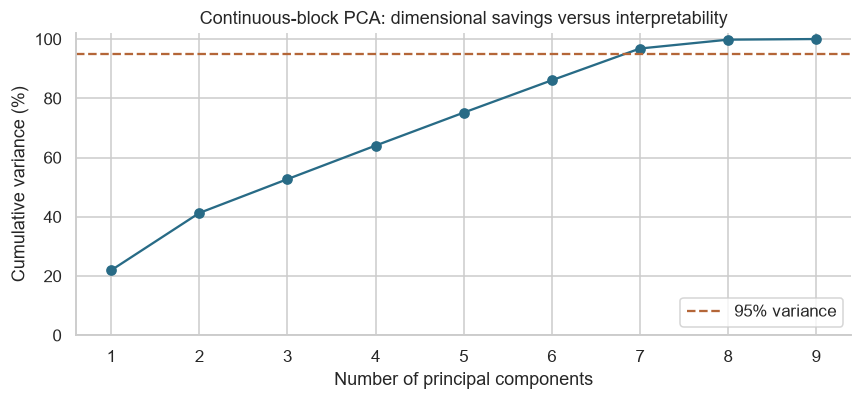

In [11]:
continuous_columns = [
    "Age",
    "Tenure_Months",
    "Avg_Daily_Usage_Minutes",
    "Inactivity_Days",
    "Monthly_Charges",
    "Total_Charges",
    "Avg_Resolution_Time_Hours",
    "Engagement_Index",
    "Historical_Charge_Ratio",
]
pca_columns = [
    ("log__" if c in log_columns else "numeric__") + c for c in continuous_columns
]
pca_scaler = StandardScaler()
pca_train = pca_scaler.fit_transform(train_features[pca_columns])
pca = PCA(svd_solver="full").fit(pca_train)
cumulative_variance = np.cumsum(pca.explained_variance_ratio_)
components_90 = int(np.searchsorted(cumulative_variance, 0.90) + 1)
components_95 = int(np.searchsorted(cumulative_variance, 0.95) + 1)
variance_table = pd.DataFrame(
    {
        "Component": np.arange(1, len(pca_columns) + 1),
        "Explained variance": pca.explained_variance_ratio_,
        "Cumulative variance": cumulative_variance,
    }
)
print("Table D4 — PCA diagnostic on nine standardized continuous training features")
display(variance_table)
print("Components for ≥90% / ≥95% variance:", components_90, "/", components_95)
print(
    "Whole matrix dimension if replacing only this block at 95%:",
    train_features.shape[1] - len(pca_columns) + components_95,
)
print("Table D5 — first two component coefficient directions (not causal effects)")
display(
    pd.DataFrame(
        pca.components_[:2].T,
        index=continuous_columns,
        columns=["PC1 coefficient", "PC2 coefficient"],
    )
)
print("Figure D1 — cumulative variance in the continuous-block PCA diagnostic")
fig, ax = plt.subplots(figsize=(8, 3.8))
ax.plot(
    variance_table.Component, cumulative_variance * 100, marker="o", color="#286B86"
)
ax.axhline(95, color="#B46638", linestyle="--", label="95% variance")
ax.set(
    xlabel="Number of principal components",
    ylabel="Cumulative variance (%)",
    ylim=(0, 102),
    xticks=variance_table.Component,
    title="Continuous-block PCA: dimensional savings versus interpretability",
)
ax.legend(loc="lower right")
fig.tight_layout()
plt.show()
# Transform, rather than fit, the held-out block to verify diagnostic compatibility.
pca_holdout = pca.transform(pca_scaler.transform(holdout_features[pca_columns]))[
    :, :components_95
]
assert pca_holdout.shape == (len(X_holdout), components_95)


Seven components retain 96.80% of the continuous block's variance and satisfy both the 90% and 95% thresholds. Replacing nine measures with these components would reduce the whole matrix from 51 to 49 columns. PC1 mainly describes shared tenure/lifetime-charge variation; the signs of component coefficients are arbitrary. These limited savings do not justify replacing named business measures with component scores. Variance preservation is not evidence of preserving churn-related information.

I therefore **exclude PCA from the final pipeline** and retain all selected, named features. This avoids mixing service categories into a continuous projection and keeps price, activity and support quantities interpretable. The separate fitted PCA object is an analysis tool, not a transformation applied to the final dataset.

In [12]:
# Full-file audit describes extent only; it does not tune the fitted pipeline.
full_quality = {
    "Inactivity above 31 days": int(raw.Inactivity_Days.gt(31).sum()),
    "Device/internet contradictions": int(
        (
            raw.Device_Protection.eq("No Internet")
            != raw.Internet_Service_Type.eq("None")
        ).sum()
    ),
}
print("Table D6 — full-file extent of the training-identified quality issues")
display(pd.Series(full_quality, name="Customers").to_frame())

# Check semantics against source rows, rather than just output dimensions.
positive_support = X_train.Support_Tickets_Count.gt(0)
np.testing.assert_allclose(
    train_semantic.loc[positive_support, "Unresolved_Support_Ratio"],
    X_train.loc[positive_support, "Unresolved_Tickets_Count"]
    / X_train.loc[positive_support, "Support_Tickets_Count"],
)
assert (
    train_semantic.loc[X_train.Support_Tickets_Count.eq(0), "Unresolved_Support_Ratio"]
    .eq(0)
    .all()
)
np.testing.assert_allclose(
    train_semantic.Historical_Charge_Ratio,
    X_train.Total_Charges / (X_train.Tenure_Months * X_train.Monthly_Charges),
    equal_nan=True,
)
assert train_features.index.equals(X_train.index) and holdout_features.index.equals(
    X_holdout.index
)
assert train_features.columns.equals(holdout_features.columns)
assert len(train_features) + len(holdout_features) == len(raw)
assert (
    np.isfinite(train_features.to_numpy()).all()
    and np.isfinite(holdout_features.to_numpy()).all()
)
assert all(pd.api.types.is_numeric_dtype(t) for t in train_features.dtypes)
assert not any("Churn" in c or "Customer_ID" in c for c in train_features.columns)

# Deliberately challenge the stated future-input policy without refitting.
probe = X_holdout.iloc[:3].copy()
probe.iloc[0, probe.columns.get_loc("Region")] = "Unseen region"
probe.iloc[0, probe.columns.get_loc("Support_Tickets_Count")] = 0
probe.iloc[0, probe.columns.get_loc("Unresolved_Tickets_Count")] = 0
probe.iloc[1, probe.columns.get_loc("Monthly_Charges")] = 0
probe.iloc[1, probe.columns.get_loc("Engagement_Index")] = np.nan
probe.iloc[2, probe.columns.get_loc("Inactivity_Days")] = 60
probe_semantic = clean_and_construct(probe)
assert probe_semantic.Unresolved_Support_Ratio.iloc[0] == 0
assert pd.isna(probe_semantic.Historical_Charge_Ratio.iloc[1])
assert pd.isna(probe_semantic.Inactivity_Days.iloc[2])
fitted = feature_pipeline.named_steps["preprocess"]
before = [
    (name, fitted.named_transformers_[name].named_steps["impute"].statistics_.copy())
    for name in ["log", "numeric", "ratings"]
]
probe_features = feature_pipeline.transform(probe)
assert (
    probe_features.columns.equals(train_features.columns)
    and np.isfinite(probe_features.to_numpy()).all()
)
assert probe_features.filter(like="nominal__Region_").iloc[0].eq(0).all()
for name, original_statistics in before:
    np.testing.assert_array_equal(
        original_statistics,
        fitted.named_transformers_[name].named_steps["impute"].statistics_,
    )
pd.testing.assert_frame_equal(holdout_features, feature_pipeline.transform(X_holdout))
refitted_features = clone(feature_pipeline).fit_transform(X_train)
pd.testing.assert_frame_equal(train_features, refitted_features)
try:
    feature_pipeline.transform(X_holdout.drop(columns="Monthly_Charges"))
except ValueError as exc:
    assert "Required raw predictor columns" in str(exc)
else:
    raise AssertionError("Missing required columns should be rejected explicitly.")
print(
    "Pipeline validation PASSED: correct formulas; zero denominators; missing and invalid values;"
)
print(
    "stable numeric schema; preserved customer order; no target/identifier; unknown categories;"
)
print(
    "unchanged imputation values; repeatable transform; reproducible fitting; explicit schema errors."
)
print("All 5,000 customers are represented across training and held-out matrices.")


Table D6 — full-file extent of the training-identified quality issues


,Customers
Inactivity above 31 days,364
Device/internet contradictions,1280


Pipeline validation PASSED: correct formulas; zero denominators; missing and invalid values;
stable numeric schema; preserved customer order; no target/identifier; unknown categories;
unchanged imputation values; repeatable transform; reproducible fitting; explicit schema errors.
All 5,000 customers are represented across training and held-out matrices.


The required raw schema is the 25 original predictors listed in Table C3; both ratios are created inside the pipeline. Extra raw columns are ignored, except that a supplied `Churn` column is rejected. Required columns must be present: an absent column is a schema error, whereas missing cell values follow the stated imputation policy. The code supports compatible customer records, not arbitrary schemas or unverified future business definitions.

The billing-ratio and total-charge missingness flags coincide on the supplied data because the ratio inherits missing total charges. I retain the ratio flag for its distinct meaning when a future denominator is zero; there it can differ from the total-charge flag. This small redundancy is deliberate and should be reconsidered for a future model that is sensitive to collinearity.

The final matrices remain available as `train_features` and `holdout_features`; labels remain in `y_train` and `y_holdout`. To transform another compatible DataFrame, call `feature_pipeline.transform(new_customers)` and reuse the fitted parameters. I do not export extra submission files. A downstream model should use this pipeline within each training/CV fold, rather than reusing medians from a different fold. Any final refit on all available development data belongs to that later modelling process.

## Part E — Summary and reflection
My main lesson was that correct interpretation precedes transformation. A default CSV parser would have converted valid “None” service labels into missing data. I also had to distinguish a support-free resolution time from an unknown duration and a genuine extreme from a value inconsistent with the stated monthly window. Excluding an unreliable cross-system field was more defensible than guessing its correct value.

I preserved customers, used training-only imputation and robust scaling, and applied logarithms selectively. Two guarded ratios describe support backlog and historical billing relative to present price. Their usefulness remains to be tested: the billing ratio has little variation, and the unresolved-support ratio assumes compatible ticket windows. Removing rounded, estimated and thresholded duplicates improves clarity without assuming that every correlated predictor is dispensable.

The reusable pipeline gives consistent numerical columns, makes its schema explicit and transforms held-out customers without refitting. PCA was assessed on a scaled continuous block but omitted from the final representation because its limited dimensional savings did not justify losing business labels. No classification accuracy or predictive benefit is claimed.

The file is synthetic, lacks timestamps and does not establish causal relationships. Before deployment I would confirm feature availability before churn, the inactivity window, ticket-cohort definitions, billing alignment and data-source reliability. I would monitor missingness and unseen categories, review demographic fairness, and test the candidate features with temporal/external validation. This assignment establishes a reproducible preprocessing basis for that work rather than a validated retention model.

In [13]:
results = {
    "raw_rows": len(raw),
    "raw_columns": raw.shape[1],
    "churned": int(y.sum()),
    "training_rows": len(X_train),
    "holdout_rows": len(X_holdout),
    "semantic_features": len(selected_columns),
    "encoded_features": train_features.shape[1],
    "missing_counts": missing.astype(int).to_dict(),
    "training_missing_counts": X_train.isna()
    .sum()
    .loc[lambda s: s.gt(0)]
    .astype(int)
    .to_dict(),
    "full_quality": full_quality,
    "pca_components_90": components_90,
    "pca_components_95": components_95,
    "pca_variance_95": float(cumulative_variance[components_95 - 1]),
    "pca_matrix_dimension": train_features.shape[1] - len(pca_columns) + components_95,
    "selected_columns": selected_columns,
    "encoded_columns": train_features.columns.tolist(),
    "pca_pc1": dict(zip(continuous_columns, pca.components_[0].tolist())),
    "log_skew_before": X_train[log_columns].skew().to_dict(),
    "log_skew_after": np.log1p(X_train[log_columns]).skew().to_dict(),
}
print(
    "Final assignment summary — Parts A–E and all four LMS rubric categories addressed"
)
display(
    pd.DataFrame(
        {
            "Item": [
                "Original file",
                "Selected semantic features",
                "Training feature matrix",
                "Held-out feature matrix",
                "PCA in final pipeline",
                "Validation",
            ],
            "Result": [
                str(raw.shape),
                str(len(selected_columns)),
                str(train_features.shape),
                str(holdout_features.shape),
                "No — diagnostic only",
                "All checks passed",
            ],
        }
    )
)


Final assignment summary — Parts A–E and all four LMS rubric categories addressed


,Item,Result
0,Original file,"(5000, 32)"
1,Selected semantic features,27
2,Training feature matrix,"(4000, 51)"
3,Held-out feature matrix,"(1000, 51)"
4,PCA in final pipeline,No — diagnostic only
5,Validation,All checks passed
